In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

import pickle
import time
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
df = pd.read_csv('weather_data.csv')
df.drop(columns = ['Unnamed: 0', 'incident_latitude', 'incident_longitude', 'incident_date_created'], inplace=True)
df.head()

,fire_started?,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,True,142.0,87.857600,49.247600,49805.977,44803.945,7.70,0.0,0.0,8.815597,20.8041,0.244245,42.041668,72.0,16.0,999.06384,995.19250
1,True,634.0,81.365005,60.305000,48694.004,34689.043,8.70,0.0,0.0,25.787672,47.4244,0.356950,31.000000,37.0,9.0,937.44836,931.04100
2,False,1810.0,65.043500,33.723500,49877.473,42414.965,8.50,0.0,0.0,23.492760,31.5417,0.233666,4.708334,48.0,9.0,821.74290,813.92250
3,True,1075.0,82.297390,52.777397,49010.100,45562.844,8.60,0.0,0.0,14.085998,15.2116,0.277917,1.458333,47.0,11.0,897.75420,889.85390
4,True,452.0,93.328700,55.708702,49183.010,45576.700,8.25,0.0,0.0,21.269154,27.5151,0.318660,10.416667,62.0,9.0,962.82263,958.66864


In [3]:
output = df['fire_started?']
input = df.drop(columns = 'fire_started?')
input.head()

,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,142.0,87.857600,49.247600,49805.977,44803.945,7.70,0.0,0.0,8.815597,20.8041,0.244245,42.041668,72.0,16.0,999.06384,995.19250
1,634.0,81.365005,60.305000,48694.004,34689.043,8.70,0.0,0.0,25.787672,47.4244,0.356950,31.000000,37.0,9.0,937.44836,931.04100
2,1810.0,65.043500,33.723500,49877.473,42414.965,8.50,0.0,0.0,23.492760,31.5417,0.233666,4.708334,48.0,9.0,821.74290,813.92250
3,1075.0,82.297390,52.777397,49010.100,45562.844,8.60,0.0,0.0,14.085998,15.2116,0.277917,1.458333,47.0,11.0,897.75420,889.85390
4,452.0,93.328700,55.708702,49183.010,45576.700,8.25,0.0,0.0,21.269154,27.5151,0.318660,10.416667,62.0,9.0,962.82263,958.66864


In [4]:
ada_pickle = open('ada_ml.pickle', 'rb')
ada_ml = pickle.load(ada_pickle)
ada_pickle.close()

In [5]:
rf_pickle = open('rf_ml.pickle', 'rb')
rf_ml = pickle.load(rf_pickle)
rf_pickle.close()

In [6]:
xg_pickle = open('xg_ml.pickle', 'rb')
xg_ml = pickle.load(xg_pickle)
xg_pickle.close()

In [7]:
train_X, test_X, train_y, test_y = train_test_split(input, output, test_size = 0.2, random_state = 1)

In [8]:
ensemble_ml = VotingClassifier(estimators = [('ada', ada_ml), ('rf', rf_ml), ('xg', xg_ml)], voting = 'soft', weights = [0.323, 0.335, 0.342])

In [9]:
start = time.time()
ensemble_ml.fit(train_X, train_y)
stop = time.time()
print(f"Time Taken: {stop - start} seconds")

Time Taken: 0.55999755859375 seconds


In [10]:
y_pred = ensemble_ml.predict(test_X)

In [11]:
class_report = classification_report(test_y, y_pred, output_dict=True)
cr_df = pd.DataFrame(class_report)
cr_df.to_csv('ensemble_report.csv')
cr_df

,False,True,accuracy,macro avg,weighted avg
precision,0.930000,0.784810,0.899736,0.857405,0.898204
recall,0.942568,0.746988,0.899736,0.844778,0.899736
f1-score,0.936242,0.765432,0.899736,0.850837,0.898835
support,296.000000,83.000000,0.899736,379.000000,379.000000


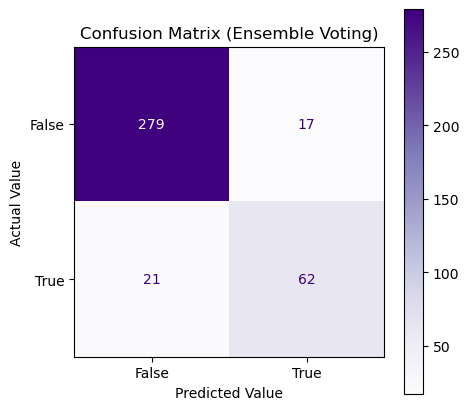

In [12]:
cm = confusion_matrix(test_y, y_pred, labels=ensemble_ml.classes_)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ensemble_ml.classes_)

fig, ax = plt.subplots(figsize=(5,5))
display.plot(cmap = "Purples", ax = ax)
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.title('Confusion Matrix (Ensemble Voting)')
plt.savefig('ensemble_matrix.svg')
fig

In [13]:
importance = ada_ml.feature_importances_
ada_feat_imp = pd.DataFrame(list(zip(train_X.columns, importance)),
                        columns = ['Feature', 'Importance'])

ada_feat_imp

,Feature,Importance
0,Elevation,0.139278
1,temperature_2m_max,0.343252
2,temperature_2m_min,0.000000
3,daylight_duration,0.137100
4,sunshine_duration,0.077038
5,uv_index_max,0.017586
6,precipitation_sum,0.000000
7,precipitation_hours,0.000000
8,wind_speed_10m_max,0.039467
9,wind_gusts_10m_max,0.000000


In [14]:
importance = rf_ml.feature_importances_
rf_feat_imp = pd.DataFrame(list(zip(train_X.columns, importance)),
                        columns = ['Feature', 'Importance'])

rf_feat_imp

,Feature,Importance
0,Elevation,0.085707
1,temperature_2m_max,0.143256
2,temperature_2m_min,0.066773
3,daylight_duration,0.086888
4,sunshine_duration,0.098005
5,uv_index_max,0.049588
6,precipitation_sum,0.002187
7,precipitation_hours,0.001384
8,wind_speed_10m_max,0.051940
9,wind_gusts_10m_max,0.044875


In [15]:
importance = xg_ml.feature_importances_
xg_feat_imp = pd.DataFrame(list(zip(train_X.columns, importance)),
                        columns = ['Feature', 'Importance'])

xg_feat_imp

,Feature,Importance
0,Elevation,0.099650
1,temperature_2m_max,0.235876
2,temperature_2m_min,0.051391
3,daylight_duration,0.091281
4,sunshine_duration,0.068207
5,uv_index_max,0.051997
6,precipitation_sum,0.021063
7,precipitation_hours,0.012618
8,wind_speed_10m_max,0.049614
9,wind_gusts_10m_max,0.031710


In [16]:
vc_feat_imp = []
for i in range(len(rf_feat_imp['Importance'])):
    x = (ada_feat_imp['Importance'][i]*0.323) + (rf_feat_imp['Importance'][i]*0.335) + (xg_feat_imp['Importance'][i]*0.342)
    vc_feat_imp.append(x)

vc_feat_imp

[np.float64(0.10777883561282545),
 np.float64(0.23953078956206914),
 np.float64(0.039944732424387924),
 np.float64(0.10460896217203919),
 np.float64(0.08104164531163155),
 np.float64(0.040074905396518215),
 np.float64(0.007936191735824718),
 np.float64(0.00477904804200856),
 np.float64(0.0471157706266837),
 np.float64(0.02587779966373069),
 np.float64(0.050482823023584956),
 np.float64(0.025704564884349877),
 np.float64(0.02267823570985828),
 np.float64(0.07819421599920426),
 np.float64(0.08689588445285716),
 np.float64(0.03735561977562719)]

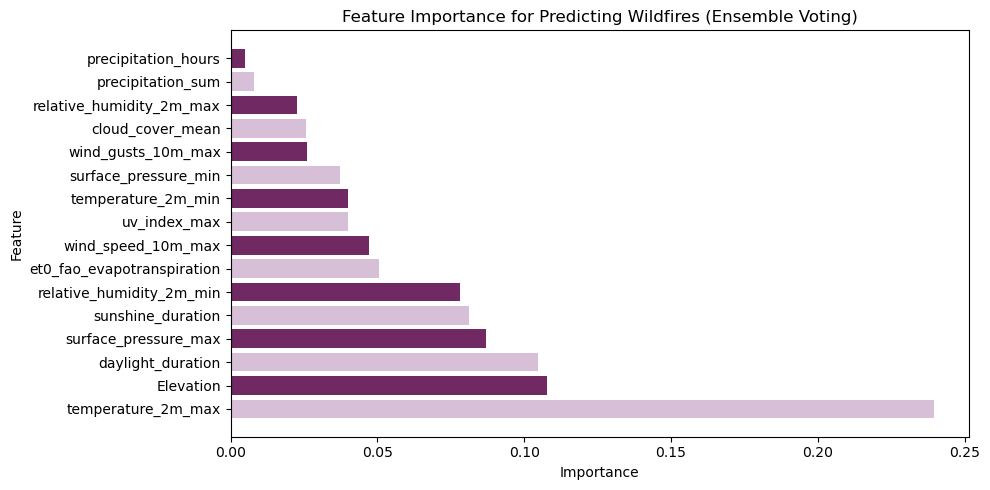

In [17]:
feat_imp = pd.DataFrame(list(zip(train_X.columns, vc_feat_imp)),
                        columns = ['Feature', 'Importance'])

feat_imp = feat_imp.sort_values(by = 'Importance', ascending=False).reset_index(drop=True)

feat_imp_chart = plt.figure(figsize=(10, 5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color = ['#D8BFD8', '#702963'])

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance for Predicting Wildfires (Ensemble Voting)')
plt.tight_layout()
plt.savefig('ensemble_importance.svg')
feat_imp_chart

In [18]:
probability = ensemble_ml.predict_proba(test_X)
fire_probability = []
for i in probability:
    fire_probability.append(i[1])

fire_probability

[np.float64(0.08482535363108583),
 np.float64(0.765819388076636),
 np.float64(0.4215047666328407),
 np.float64(0.7940632363213568),
 np.float64(0.14636260467133058),
 np.float64(0.12233463262728277),
 np.float64(0.35311919267311564),
 np.float64(0.09987321476941532),
 np.float64(0.08732833579918062),
 np.float64(0.21974727482508172),
 np.float64(0.11714584168445924),
 np.float64(0.40477810252181007),
 np.float64(0.262018935489626),
 np.float64(0.09928195833772614),
 np.float64(0.14156039276126975),
 np.float64(0.07816501389787076),
 np.float64(0.1208806118157418),
 np.float64(0.12032057147073992),
 np.float64(0.19513266659930864),
 np.float64(0.49218487335614924),
 np.float64(0.20531678319420665),
 np.float64(0.8163796534804904),
 np.float64(0.10767015390773105),
 np.float64(0.09142971414857534),
 np.float64(0.18287649345972776),
 np.float64(0.6111538432496048),
 np.float64(0.14124874676952653),
 np.float64(0.11399954148126906),
 np.float64(0.7809522774398302),
 np.float64(0.2026720673

In [19]:
ensemble_pickle = open('ensemble_ml.pickle', 'wb')
pickle.dump(ensemble_ml, ensemble_pickle)
ensemble_pickle.close()